# Predicting drug resistance from single-cell transcriptomes


## Setup


In [20]:
import sys
import zipfile
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.metrics import average_precision_score, f1_score, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from xgboost import XGBClassifier

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.py").exists())
sys.path.insert(0, str(ROOT))

import config as C
from src import blosum_of, save_plot

In [21]:
COELHO = C.DATA / "source" / "coelho2024"
SUPPLEMENT = COELHO / "41588_2024_1948_MOESM4_ESM.xlsx"
COUNTS_ZIP = COELHO / "logcounts_ABE.zip"
FACTOR_COUNTS = [5, 10, 15, 20, 25]
DRAWS = 10          # control downsamples, as in notebook 04
SEEDS = 3           # each sets the split and the classifier's own subsampling
FOLDS = 5
HIGH_VARIANCE_GENES = 2000
RESISTANCE, CONTROL = "Resistance", "Control"

## The cells


In [22]:
meta = pd.read_csv(COELHO / "meta_ABE.csv", index_col=0, low_memory=False)
meta.variant_class_highest_impact.value_counts().rename("cells").to_frame()

,cells
variant_class_highest_impact,
control,8534
drug addiction,590
canonical drug resistance,381


In [23]:
def guides_of(cell_name):
    """The guide identifiers in a cell name, dropping the iBAR parts."""
    return [part for part in str(cell_name).split("-") if not part.startswith("iBAR_")]

In [24]:
meta["guide_list"] = [guides_of(name) for name in meta.index]
meta["n_guides"] = meta.guide_list.str.len()
meta["labels_in_cell"] = [len(set(str(v).split("-"))) for v in meta.variant_class]

In [25]:
meta["class_list"] = [str(v).split("-") for v in meta.variant_class]
assert (meta.class_list.str.len() == meta.n_guides).all(), "class list does not align"


def attributed_guide(parts, classes):
    """The guide a cell's phenotype belongs to, or None when it cannot be attributed.

    One guide: itself. Two guides of which exactly one is a control: the non-control
    one, since the control is taken to be inert. Anything else is unattributable.
    """
    if len(parts) == 1:
        return parts[0]
    if len(parts) == 2:
        variant = [part for part, name in zip(parts, classes) if name != "control"]
        if len(variant) == 1:
            return variant[0]
    return None

In [ ]:
meta["attributed"] = [
    attributed_guide(parts, classes)
    for parts, classes in zip(meta.guide_list, meta.class_list)
]
usable = meta[meta.attributed.notna()].copy()
usable["label"] = np.where(
    usable.variant_class_highest_impact.eq("control"), CONTROL, RESISTANCE
)
single = usable.n_guides == 1
assert (usable.loc[single, "attributed"] == usable.loc[single, "gRNA"]).all()

In [27]:
pd.DataFrame(
    {"cells": [
        len(meta),
        int((meta.n_guides == 1).sum()),
        int(((meta.n_guides == 2) & meta.attributed.notna()).sum()),
        -int(meta.attributed.isna().sum()),
        len(usable),
        int(usable.label.eq(RESISTANCE).sum()),
    ]},
    index=["published", "one guide", "two guides, one a control",
           "unattributable, dropped", "usable", "of which resistance"],
)

,cells
published,9505
one guide,7251
"two guides, one a control",251
"unattributable, dropped",-2003
usable,7502
of which resistance,846


In [28]:
per_label = usable.groupby("attributed").label.first().value_counts()
print(f"{usable.attributed.nunique()} variants over {len(usable):,} cells: "
      f"{per_label[RESISTANCE]} resistance, {per_label[CONTROL]} control")
usable.groupby("variant_class_highest_impact").agg(
    cells=("attributed", "size"), variants=("attributed", "nunique")
)

216 variants over 7,502 cells: 20 resistance, 196 control


,cells,variants
variant_class_highest_impact,,
canonical drug resistance,335,8
control,6656,196
drug addiction,511,12


## Linking the guides to the variant annotations


In [29]:
st6 = pd.read_excel(SUPPLEMENT, sheet_name="ST6 perturb-seq")
st6["short"] = st6.sgRNA_ID.astype(str).str[:6]
assert st6.short.is_unique, "the six character prefix is not unique in ST6"
short_to_sequence = st6.set_index("short").sequence.astype(str).str.upper()

In [30]:
library = pd.read_csv(C.dataset_file(C.COELHO_STUDY, "library"))
library["upper"] = library.guide.astype(str).str.upper()
by_suffix = {}
for guide in library.upper:
    by_suffix.setdefault(guide[1:], []).append(guide)

In [31]:
records = []
for identifier in usable.gRNA.unique():
    for part in guides_of(identifier):
        gene, _, short = part.rpartition("_")
        sequence = short_to_sequence.get(short)
        candidates = by_suffix.get(sequence, []) if isinstance(sequence, str) else []
        records.append({
            "part": part,
            "gene_label": gene,
            "candidates": len(candidates),
            "guide": candidates[0] if len(candidates) == 1 else None,
        })
link = pd.DataFrame(records).drop_duplicates("part")

In [ ]:
annotation = pd.read_csv(C.dataset_file(C.COELHO_STUDY, "annotation"), low_memory=False)
annotation = annotation[annotation.editor == "ABE"]

EDIT_KEY = ["chromosome", "position", "genomic_ref", "genomic_alt"]
structure = pd.read_csv(C.DATA / "features_variant_structure.csv")
structure = structure.astype({"chromosome": annotation.chromosome.dtype})
PROTVAR = [c for c in structure.columns if c not in EDIT_KEY + ["gene", "uniprot",
           "residue", "wild_type", "mutant", "protvar_annotated"]]
annotation = annotation.merge(
    structure[EDIT_KEY + PROTVAR].drop_duplicates(EDIT_KEY), on=EDIT_KEY, how="left"
)
annotation["blosum62"] = blosum_of(annotation.vep_aaref, annotation.vep_aaalt)
reached = link.dropna(subset=["guide"]).merge(
    annotation.drop_duplicates("guide")[["guide", "gene"]], on="guide", how="left"
)
agree = reached.dropna(subset=["gene"])
print(f"{len(link)} identifiers, {int(link.candidates.eq(1).sum())} resolved, "
      f"{int(reached.gene.notna().sum())} annotated, gene label agrees "
      f"{(agree.gene_label == agree.gene).mean():.0%}")

216 identifiers, 216 resolved, 133 annotated, gene label agrees 100%


/var/folders/5v/3w39hhps0k15qx5v_t82tpvh0000gn/T/ipykernel_85505/602961706.py:14: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  annotation["blosum62"] = blosum_of(annotation.vep_aaref, annotation.vep_aaalt)


## The variant features


In [ ]:
guide_of_part = link.dropna(subset=["guide"]).set_index("part").guide
relevant = annotation[annotation.guide.isin(set(guide_of_part))]
relevant.codon_mutation_category.value_counts().rename("edits").to_frame()

,edits
codon_mutation_category,
Missense,138
Silent,17
Intron,4
Splice-acceptor,1


In [ ]:
DICTIONARY = pd.read_csv(C.DATA / "model_matrix_features.csv", index_col="feature")
VEP_FEATURES = list(DICTIONARY.index[DICTIONARY.group.isin(["annotation", "protvar"])])
ONE_HOT = [c for c in VEP_FEATURES
           if c.startswith(("consequence_", "impact_", "am_class_"))]
SPLICE_DELTAS = [c for c in VEP_FEATURES if c.startswith("spliceai_ds_")]
NUMERIC_FEATURES = [c for c in VEP_FEATURES
                    if c not in ONE_HOT + SPLICE_DELTAS + ["splice_scored"]]
missing = [c for c in NUMERIC_FEATURES + SPLICE_DELTAS if c not in relevant.columns]
assert not missing, f"notebook 04 uses features absent from this annotation: {missing}"
print(f"{len(VEP_FEATURES)} features from notebook 04: {len(NUMERIC_FEATURES)} numeric, "
      f"{len(SPLICE_DELTAS)} splice, {len(ONE_HOT)} one-hot, "
      f"{len(relevant) / relevant.guide.nunique():.2f} edits per guide")
DICTIONARY.loc[VEP_FEATURES].group.value_counts().rename("features").to_frame()

76 features from notebook 04: 52 numeric, 4 splice, 19 one-hot, 1.77 edits per guide


,features
group,
annotation,74
protvar,2


In [ ]:
numeric = relevant[NUMERIC_FEATURES + SPLICE_DELTAS].apply(pd.to_numeric, errors="coerce")
one_hot = pd.get_dummies(
    pd.DataFrame({
        "consequence": relevant.vep_Consequence.astype(str).str.split(",").str[0],
        "impact": relevant.vep_IMPACT,
        "am_class": relevant.vep_am_class,
    }),
    prefix_sep="_", dtype=float,
)
block = pd.concat([numeric, one_hot], axis=1)
block["splice_scored"] = relevant[SPLICE_DELTAS].notna().any(axis=1).astype(float)
block[SPLICE_DELTAS] = block[SPLICE_DELTAS].fillna(0.0)


per_guide = (
    block.groupby(relevant.guide).mean().reindex(columns=VEP_FEATURES, fill_value=0.0)
)
print(f"{len(per_guide):,} guides x {per_guide.shape[1]} features; "
      f"{len([c for c in ONE_HOT if block.get(c) is None])} one-hot levels absent here")
per_guide.head()

133 guides x 76 features; 4 one-hot levels absent here


,vep_GERP++_NR,vep_GERP++_RS,blosum62,vep_phastCons100way_vertebrate,vep_phastCons17way_primate,vep_phyloP100way_vertebrate,vep_phyloP17way_primate,vep_phyloP470way_mammalian,vep_GERP_92_mammals,vep_MAX_AF,...,am_class_ambiguous,am_class_likely_benign,am_class_likely_pathogenic,spliceai_ds_ag,spliceai_ds_al,spliceai_ds_dg,spliceai_ds_dl,splice_scored,foldx_ddg,plddt
guide,,,,,,,,,,,,,,,,,,,,,
AAAATTCACCGCAGTGCATC,5.82,5.24,1.5,1.0,1.0,8.017,0.665,7.8985,3.97,NaN,...,0.0,0.0,1.0,0.050,0.0,0.0,0.00,1.0,0.144187,49.89
AACAGGCACCAGAAGTCATC,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000002,...,0.0,0.0,0.0,0.335,0.5,0.0,0.00,1.0,NaN,NaN
AAGGAGGCCCAAAAGCGACA,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.000,0.0,0.0,0.00,1.0,NaN,NaN
ACAAAATAAATCACAAAAAA,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.000,0.0,0.0,0.00,0.0,NaN,NaN
ACAAGCCACTCACCAGGCAC,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.000,0.0,0.0,0.01,1.0,NaN,NaN


In [36]:
aa_parts = annotation.vep_Amino_acids.astype(str).str.split("/")
residue = (
    pd.to_numeric(annotation.vep_Protein_position.astype(str).str.split("-").str[0],
                  errors="coerce")
    .astype("Int64").astype(str)
)
detail = (
    annotation.assign(
        substitution=np.where(
            annotation.vep_Amino_acids.notna(),
            aa_parts.str[0] + residue + aa_parts.str[-1],
            None,
        )
    )
    .groupby("guide")
    .agg(
        gene=("gene", "first"),
        substitution=("substitution", lambda s: "|".join(dict.fromkeys(s.dropna()))),
        consequence=("vep_Consequence", lambda s: "|".join(dict.fromkeys(s.dropna()))),
        edits=("guide", "size"),
    )
)
called = usable[usable.variant_class_highest_impact != "control"]
listing = (
    called.groupby(["variant_class_highest_impact", "attributed"])
    .size().rename("cells").reset_index()
    .rename(columns={"variant_class_highest_impact": "class", "attributed": "guide_id"})
)
listing["guide"] = listing.guide_id.map(guide_of_part)
listing = listing.join(detail, on="guide").drop(columns="guide")
listing["annotated"] = listing.gene.notna()
listing = listing.sort_values(["class", "cells"], ascending=[True, False])
print(f"{int(listing.annotated.sum())} of {len(listing)} called variants carry an "
      f"annotation; the rest are in the perturb-seq validation library but not in the "
      f"screen library, so they have no VEP features")
listing.reset_index(drop=True)

/var/folders/5v/3w39hhps0k15qx5v_t82tpvh0000gn/T/ipykernel_85505/3522364653.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  annotation.assign(


17 of 20 called variants carry an annotation; the rest are in the perturb-seq validation library but not in the screen library, so they have no VEP features


,class,guide_id,cells,gene,substitution,consequence,edits,annotated
0,canonical drug resistance,EGFR_82f3b9,81,EGFR,F436L|F436S|F436F,missense_variant|synonymous_variant,3.0,True
1,canonical drug resistance,BRAF_5802f4,53,BRAF,S365P|S364P,missense_variant,2.0,True
2,canonical drug resistance,KRAS_33f23d,50,KRAS,K117K|K117R,synonymous_variant|missense_variant,2.0,True
3,canonical drug resistance,MAP2K1_18db13,49,NaN,NaN,NaN,NaN,False
4,canonical drug resistance,EGFR_cd8f82,34,EGFR,N493D|N493S,missense_variant,2.0,True
5,canonical drug resistance,BRAF_82dc01,28,BRAF,S365P,missense_variant,1.0,True
6,canonical drug resistance,MAP2K1_273ccb,21,MAP2K1,Q45R|Q46R,missense_variant,2.0,True
7,canonical drug resistance,MAP2K1_ae4498,19,NaN,NaN,NaN,NaN,False
8,drug addiction,MAP2K1_a2b2c6,105,MAP2K1,S194P,missense_variant,1.0,True
9,drug addiction,MAP2K1_4802a9,86,MAP2K1,Y130C,missense_variant,1.0,True


## The expression matrix


In [37]:
def stream_rows(chunksize=4000):
    """The log-counts matrix in chunks, since it does not fit comfortably in memory."""
    with zipfile.ZipFile(COUNTS_ZIP) as archive:
        name = archive.namelist()[0]
        with archive.open(name) as handle:
            yield from pd.read_csv(handle, index_col=0, chunksize=chunksize)

In [38]:
variances, names = [], []
for chunk in stream_rows():
    variances.append(chunk.to_numpy(dtype=np.float32).var(axis=1))
    names.extend(chunk.index)
variance = pd.Series(np.concatenate(variances), index=names)
chosen = set(variance.nlargest(HIGH_VARIANCE_GENES).index)

In [39]:
blocks = [
    chunk.loc[chunk.index.isin(chosen)].astype(np.float32)
    for chunk in stream_rows()
]
expression = pd.concat([b for b in blocks if len(b)]).T  # cells by genes
assert expression.index.equals(meta.index), "cell order differs from the metadata"
expression = expression.loc[usable.index]
print(f"{len(variance):,} genes measured, {expression.shape[1]:,} kept, "
      f"{expression.shape[0]:,} cells")

36,601 genes measured, 2,000 kept, 7,502 cells


## Factors


In [40]:
standardised = expression.to_numpy(dtype=np.float32)
standardised = (standardised - standardised.mean(axis=0)) / (standardised.std(axis=0) + 1e-8)
factors, explained = {}, {}
for count in FACTOR_COUNTS:
    reducer = PCA(n_components=count, random_state=0)
    factors[count] = reducer.fit_transform(standardised)
    explained[count] = reducer.explained_variance_ratio_.sum()
pd.Series(explained, name="variance explained").rename_axis("factors").to_frame()

,variance explained
factors,
5,0.106880
10,0.136269
15,0.149104
20,0.158780
25,0.166827


### Variant arm


In [ ]:
def vep_rows(frame):
    guides = frame.attributed.map(guide_of_part)
    return per_guide.reindex(guides).to_numpy(dtype=np.float32)

In [42]:
vep_matrix = vep_rows(usable)
covered = np.isfinite(vep_matrix).any(axis=1)
by_label = usable.assign(covered=covered).groupby("label").covered.mean()
print(f"cells with any variant feature: {covered.mean():.0%} overall, "
      f"{by_label[CONTROL]:.0%} of control against {by_label[RESISTANCE]:.0%} of resistance")

cells with any variant feature: 58% overall, 54% of control against 88% of resistance


## Classifiers


In [43]:
HYPERPARAMETERS = dict(
    objective="binary:logistic", tree_method="hist", n_estimators=300, max_depth=4,
    learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, eval_metric="logloss",
)
labels = usable.label.eq(RESISTANCE).astype(int).to_numpy()
groups = usable.attributed.to_numpy()
gene_of = usable.attributed.str.split("_").str[0].to_numpy()

In [44]:
def stratified_sample(index, target, generator):
    """`target` rows drawn from `index`, keeping each gene's share, as in notebook 04."""
    if len(index) <= target:
        return index
    fraction = target / len(index)
    return np.concatenate([
        generator.choice(rows.to_numpy(),
                         size=min(len(rows), max(1, round(len(rows) * fraction))),
                         replace=False)
        for _, rows in pd.Series(index).groupby(gene_of[index])
    ])


def downsample_training(index, generator):
    """Control cells cut to the resistance count, inside the training part only."""
    resistant = index[labels[index] == 1]
    control = stratified_sample(index[labels[index] == 0], len(resistant), generator)
    return np.concatenate([resistant, control])

In [45]:
def cross_validate(features, index, seed, grouped=True):
    """Out-of-fold predictions over the downsampled set, folds grouped by variant."""
    subset, truth = features[index], labels[index]
    unit = groups[index] if grouped else np.arange(len(index))
    probability = np.zeros(len(index))
    train_auc = []
    splitter = StratifiedGroupKFold(FOLDS, shuffle=True, random_state=seed)
    for train, test in splitter.split(subset, truth, unit):
        model = XGBClassifier(random_state=seed, **HYPERPARAMETERS)
        model.fit(subset[train], truth[train])
        probability[test] = model.predict_proba(subset[test])[:, 1]
        train_auc.append(roc_auc_score(
            truth[train], model.predict_proba(subset[train])[:, 1]
        ))
    test_auc = roc_auc_score(truth, probability)
    return {
        "test auc": test_auc,
        "test ap": average_precision_score(truth, probability),
        "test prevalence": float(truth.mean()),
        "test macro f1": f1_score(
            truth, (probability >= 0.5).astype(int), average="macro"
        ),
        "train auc": float(np.mean(train_auc)),
        "gap": float(np.mean(train_auc)) - test_auc,
    }

In [46]:
def run(count, with_vep, grouped=True):
    """One row per repeat: every control downsample crossed with every seed."""
    features = np.hstack([factors[count], vep_matrix]) if with_vep else factors[count]
    rows = []
    for draw, seed in product(range(DRAWS), range(SEEDS)):
        generator = np.random.default_rng(draw)
        index = downsample_training(np.arange(len(labels)), generator)
        rows.append({
            "factors": count,
            "arm": "factors + VEP" if with_vep else "factors only",
            **cross_validate(features, index, seed, grouped),
        })
    return pd.DataFrame(rows)

In [47]:
results = pd.concat(
    [run(count, with_vep) for count in FACTOR_COUNTS for with_vep in (False, True)],
    ignore_index=True,
)
summary = results.groupby(["arm", "factors"]).mean(numeric_only=True)
summary

test auc   test ap  test prevalence  test macro f1  \
arm           factors                                                       
factors + VEP 5        0.798535  0.851914         0.500296       0.737616   
              10       0.824022  0.872645         0.500296       0.760910   
              15       0.835711  0.880897         0.500296       0.770482   
              20       0.841335  0.884607         0.500296       0.772213   
              25       0.842266  0.885356         0.500296       0.771428   
factors only  5        0.711009  0.707130         0.500296       0.654890   
              10       0.797893  0.819415         0.500296       0.728305   
              15       0.807876  0.833127         0.500296       0.743240   
              20       0.816567  0.843191         0.500296       0.752573   
              25       0.820366  0.848234         0.500296       0.754566   

                       train auc       gap  
arm           factors                       
factors + VEP 5         0.999693  0.201157  
              10        0.999978  0.175956  
              15        0.999992  0.164282  
              20        0.999997  0.158662  
              25        0.999999  0.157733  
factors only  5         0.962661  0.251652  
              10        0.992795  0.194902  
              15        0.997589  0.189713  
              20        0.998930  0.182363  
              25        0.999453  0.179087

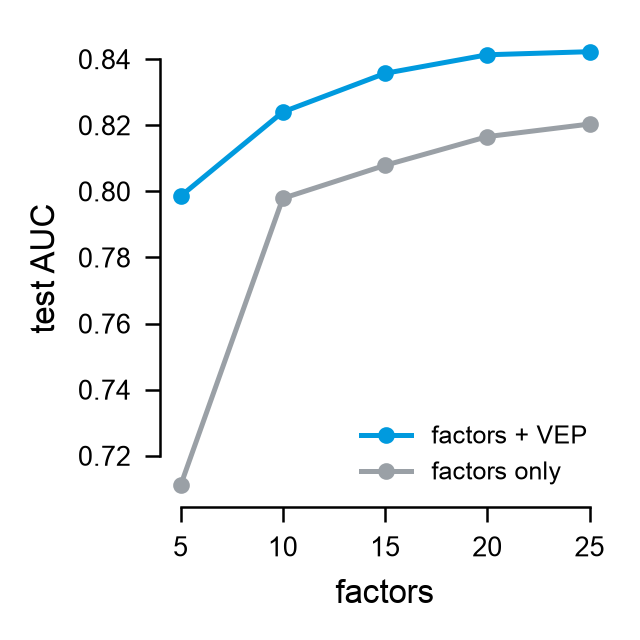

In [68]:
COLOUR = {"factors only": "#9aa0a6", "factors + VEP": "#009ADE"}

fig, ax = plt.subplots(figsize=(2, 2))
for arm, block in summary.reset_index().groupby("arm"):
    ax.plot(block.factors, block["test auc"], marker="o", ms=3, lw=1.2,
            color=COLOUR[arm], label=arm)
ax.set_xlabel("factors")
ax.set_xticks(FACTOR_COUNTS)
ax.set_ylabel("test AUC")
ax.tick_params(labelsize=6.5)
ax.legend(frameon=False, fontsize=6, loc="lower right")
fig.tight_layout(pad=0.3)
save_plot(fig, "perturbseq_factors_vs_vep")
plt.show()

In [49]:
rows = []
for metric in ["test auc", "test ap", "test macro f1", "gap"]:
    for count in FACTOR_COUNTS:
        block = results[results.factors == count]
        with_vep = block[block.arm == "factors + VEP"][metric].to_numpy()
        without = block[block.arm == "factors only"][metric].to_numpy()
        difference = with_vep - without
        error = difference.std(ddof=1) / np.sqrt(len(difference))
        rows.append({
            "metric": metric, "factors": count, "difference": difference.mean(),
            "paired se": error, "|t|": abs(difference.mean() / error),
            "positive": f"{int((difference > 0).sum())}/{len(difference)}",
        })
pd.DataFrame(rows).set_index(["metric", "factors"])

difference  paired se        |t| positive
metric        factors                                           
test auc      5          0.087526   0.002953  29.638406    30/30
              10         0.026129   0.002156  12.122093    30/30
              15         0.027835   0.002242  12.416467    30/30
              20         0.024768   0.002129  11.632957    30/30
              25         0.021900   0.002034  10.767733    30/30
test ap       5          0.144784   0.003459  41.855329    30/30
              10         0.053230   0.002621  20.306140    30/30
              15         0.047770   0.002640  18.092202    30/30
              20         0.041416   0.001991  20.803555    30/30
              25         0.037122   0.001944  19.095865    30/30
test macro f1 5          0.082726   0.003645  22.693100    30/30
              10         0.032605   0.003563   9.150532    29/30
              15         0.027241   0.003598   7.571282    29/30
              20         0.019640   0.003776   5.201280    24/30
              25         0.016861   0.003150   5.353383    24/30
gap           5         -0.050495   0.002828  17.857728     0/30
              10        -0.018945   0.002135   8.873033     1/30
              15        -0.025431   0.002252  11.294331     0/30
              20        -0.023701   0.002143  11.057246     1/30
              25        -0.021354   0.002044  10.448847     0/30

In [50]:
GROUPING_FACTORS = 15
inflation = pd.DataFrame([
    {
        "arm": "factors + VEP" if with_vep else "factors only",
        "grouped": run(GROUPING_FACTORS, with_vep)["test auc"].mean(),
        "ungrouped": run(GROUPING_FACTORS, with_vep, grouped=False)["test auc"].mean(),
    }
    for with_vep in (False, True)
]).set_index("arm")
inflation["inflation"] = inflation.ungrouped - inflation.grouped
inflation

,grouped,ungrouped,inflation
arm,,,
factors only,0.807876,0.815142,0.007266
factors + VEP,0.835711,0.986607,0.150896


## Splitting the two resistance categories


In [51]:
SUBTYPES = ["control", "drug addiction", "canonical drug resistance"]
SUBTYPE_INDEX = {name: position for position, name in enumerate(SUBTYPES)}
subtype = usable.variant_class_highest_impact.map(SUBTYPE_INDEX).to_numpy()

MULTICLASS = dict(
    objective="multi:softprob", num_class=3, tree_method="hist", n_estimators=300,
    max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
)
pd.Series(subtype).map({v: k for k, v in SUBTYPE_INDEX.items()}).value_counts().rename(
    "cells"
).to_frame().join(
    usable.groupby("variant_class_highest_impact").attributed.nunique().rename("variants")
)

,cells,variants
control,6656,196
drug addiction,511,12
canonical drug resistance,335,8


In [52]:
def downsample_three(index, generator):
    """Each class cut to the size of the second largest, stratified by gene as in 04."""
    present = pd.Series(subtype[index]).value_counts()
    target = int(present.iloc[1]) if len(present) > 1 else len(index)
    return np.concatenate([
        stratified_sample(index[subtype[index] == position], target, generator)
        for position in range(len(SUBTYPES))
    ])

In [53]:
def run_three(count, with_vep):
    """AUPRC, AUROC and F1 per class, one row per downsample and seed."""
    features = np.hstack([factors[count], vep_matrix]) if with_vep else factors[count]
    rows = []
    for draw, seed in product(range(DRAWS), range(SEEDS)):
        generator = np.random.default_rng(draw)
        index = downsample_three(np.arange(len(subtype)), generator)
        subset, truth, unit = features[index], subtype[index], groups[index]
        probability = np.zeros((len(index), len(SUBTYPES)))
        splitter = StratifiedGroupKFold(FOLDS, shuffle=True, random_state=seed)
        for train, test in splitter.split(subset, truth, unit):
            model = XGBClassifier(random_state=seed, **MULTICLASS)
            model.fit(subset[train], truth[train])
            probability[test] = model.predict_proba(subset[test])
        predicted = probability.argmax(axis=1)
        row = {"factors": count, "arm": "factors + VEP" if with_vep else "factors only"}
        for name, position in SUBTYPE_INDEX.items():
            binary = (truth == position).astype(int)
            # average precision is the area under the precision-recall curve
            row[name] = average_precision_score(binary, probability[:, position])
            row[f"{name} AUROC"] = roc_auc_score(binary, probability[:, position])
            row[f"{name} F1"] = f1_score(binary, (predicted == position).astype(int),
                                         zero_division=0)
        row["macro F1"] = f1_score(truth, predicted, average="macro", zero_division=0)
        rows.append(row)
    return pd.DataFrame(rows)

In [54]:
three_class = pd.concat(
    [run_three(count, with_vep) for count in FACTOR_COUNTS for with_vep in (False, True)],
    ignore_index=True,
)
three_summary = three_class.groupby(["arm", "factors"]).mean(numeric_only=True)
three_summary[SUBTYPES].rename(columns={n: f"{n} AUPRC" for n in SUBTYPES})

control AUPRC  drug addiction AUPRC  \
arm           factors                                        
factors + VEP 5             0.648406              0.917163   
              10            0.688867              0.922653   
              15            0.712732              0.921805   
              20            0.727074              0.923769   
              25            0.735751              0.924849   
factors only  5             0.595305              0.658845   
              10            0.658222              0.747217   
              15            0.652418              0.771867   
              20            0.659725              0.780884   
              25            0.668790              0.785363   

                       canonical drug resistance AUPRC  
arm           factors                                   
factors + VEP 5                               0.426414  
              10                              0.430076  
              15                              0.446371  
              20                              0.462002  
              25                              0.473217  
factors only  5                               0.287246  
              10                              0.307284  
              15                              0.333377  
              20                              0.359730  
              25                              0.347175

In [55]:
three_summary[[f"{name} AUROC" for name in SUBTYPES]]

control AUROC  drug addiction AUROC  \
arm           factors                                        
factors + VEP 5             0.799341              0.908250   
              10            0.832301              0.915047   
              15            0.846562              0.914189   
              20            0.853365              0.916500   
              25            0.856680              0.919368   
factors only  5             0.721751              0.763890   
              10            0.796687              0.819036   
              15            0.805116              0.829856   
              20            0.816422              0.837569   
              25            0.821181              0.840850   

                       canonical drug resistance AUROC  
arm           factors                                   
factors + VEP 5                               0.724586  
              10                              0.743346  
              15                              0.764618  
              20                              0.776861  
              25                              0.784509  
factors only  5                               0.570577  
              10                              0.595504  
              15                              0.619397  
              20                              0.639639  
              25                              0.627365

In [56]:
three_summary[[f"{name} F1" for name in SUBTYPES] + ["macro F1"]]

control F1  drug addiction F1  \
arm           factors                                  
factors + VEP 5          0.707354           0.854584   
              10         0.732230           0.858984   
              15         0.737000           0.855134   
              20         0.739532           0.857466   
              25         0.739345           0.860441   
factors only  5          0.583978           0.626305   
              10         0.666409           0.695058   
              15         0.680078           0.717669   
              20         0.693752           0.728226   
              25         0.699607           0.726861   

                       canonical drug resistance F1  macro F1  
arm           factors                                          
factors + VEP 5                            0.212085  0.591341  
              10                           0.224075  0.605096  
              15                           0.226483  0.606205  
              20                           0.238454  0.611818  
              25                           0.242223  0.614003  
factors only  5                            0.231123  0.480468  
              10                           0.244194  0.535220  
              15                           0.284108  0.560618  
              20                           0.321541  0.581173  
              25                           0.301973  0.576147

In [57]:
balanced = downsample_three(np.arange(len(subtype)), np.random.default_rng(0))
pd.DataFrame({
    "cells": [int((subtype[balanced] == p).sum()) for p in SUBTYPE_INDEX.values()],
    "prevalence": [float((subtype[balanced] == p).mean()) for p in SUBTYPE_INDEX.values()],
}, index=SUBTYPES)

,cells,prevalence
control,512,0.377025
drug addiction,511,0.376289
canonical drug resistance,335,0.246686


In [58]:
spread = three_class.groupby(["arm", "factors"]).std(numeric_only=True)
prevalence = pd.Series(
    {name: float((subtype[balanced] == position).mean())
     for name, position in SUBTYPE_INDEX.items()},
    name="prevalence",
)
prevalence.to_frame()

,prevalence
control,0.377025
drug addiction,0.376289
canonical drug resistance,0.246686


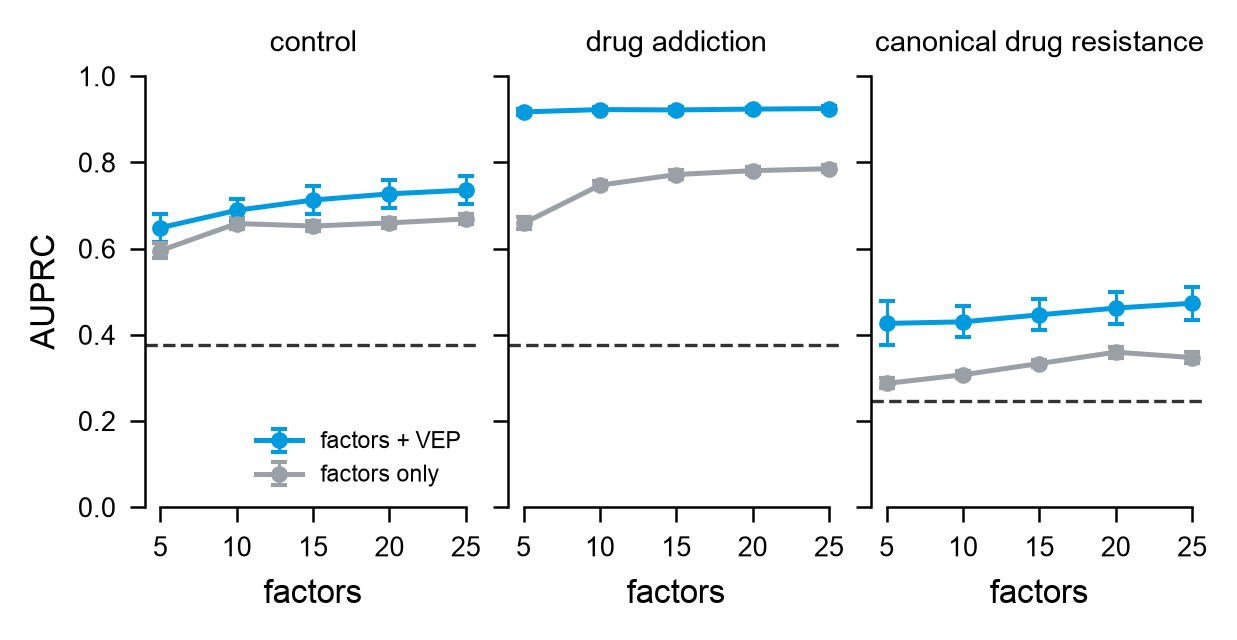

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(4, 2), sharex=True, sharey=True)
for ax, name in zip(axes, SUBTYPES):
    for arm, block in three_summary.reset_index().groupby("arm"):
        ax.errorbar(block.factors, block[name], yerr=spread.loc[arm, name].to_numpy(),
                    marker="o", ms=3, lw=1.2, color=COLOUR[arm], label=arm,
                    capsize=2, elinewidth=0.7)
    ax.axhline(prevalence[name], color="#333333", lw=0.8, ls="--")
    ax.set_title(name, fontsize=7)
    ax.set_xlabel("factors")
    ax.set_xticks(FACTOR_COUNTS)
    ax.set_ylim(0, 1)
    ax.tick_params(labelsize=6.5)
axes[0].set_ylabel("AUPRC")
axes[0].legend(frameon=False, fontsize=5.5, loc="lower right")
fig.tight_layout(pad=0.3)
save_plot(fig, "perturbseq_three_class")
plt.show()

In [60]:
rows = []
METRIC_COLUMNS = (
    SUBTYPES
    + [f"{name} AUROC" for name in SUBTYPES]
    + [f"{name} F1" for name in SUBTYPES]
    + ["macro F1"]
)
for name in METRIC_COLUMNS:
    for count in FACTOR_COUNTS:
        block = three_class[three_class.factors == count]
        with_vep = block[block.arm == "factors + VEP"][name].to_numpy()
        without = block[block.arm == "factors only"][name].to_numpy()
        difference = with_vep - without
        difference = difference[~np.isnan(difference)]
        error = difference.std(ddof=1) / np.sqrt(len(difference))
        rows.append({
            "class": name,
            "metric": ("F1" if "F1" in name else "AUROC" if "AUROC" in name else "AUPRC"),
            "factors": count, "difference": difference.mean(),
            "paired se": error, "|t|": abs(difference.mean() / error),
            "positive": f"{int((difference > 0).sum())}/{len(difference)}",
        })
pd.DataFrame(rows).set_index(["metric", "class", "factors"])

difference  paired se  \
metric class                           factors                          
AUPRC  control                         5          0.053100   0.007337   
                                       10         0.030645   0.005453   
                                       15         0.060314   0.006020   
                                       20         0.067350   0.006717   
                                       25         0.066961   0.006552   
       drug addiction                  5          0.258318   0.002513   
                                       10         0.175437   0.001834   
                                       15         0.149938   0.002125   
                                       20         0.142885   0.002092   
                                       25         0.139485   0.001916   
       canonical drug resistance       5          0.139168   0.009631   
                                       10         0.122792   0.006146   
                                       15         0.112994   0.005755   
                                       20         0.102272   0.006573   
                                       25         0.126042   0.006376   
AUROC  control AUROC                   5          0.077590   0.004109   
                                       10         0.035614   0.003020   
                                       15         0.041446   0.003125   
                                       20         0.036943   0.003008   
                                       25         0.035499   0.003029   
       drug addiction AUROC            5          0.144359   0.001852   
                                       10         0.096010   0.001367   
                                       15         0.084333   0.001595   
                                       20         0.078931   0.001583   
                                       25         0.078518   0.001513   
       canonical drug resistance AUROC 5          0.154009   0.005893   
                                       10         0.147842   0.004402   
                                       15         0.145221   0.004408   
                                       20         0.137222   0.004868   
                                       25         0.157145   0.004528   
F1     control F1                      5          0.123376   0.003587   
                                       10         0.065821   0.003283   
                                       15         0.056922   0.002498   
                                       20         0.045780   0.002861   
                                       25         0.039738   0.002725   
       drug addiction F1               5          0.228279   0.003095   
                                       10         0.163926   0.001945   
                                       15         0.137465   0.002095   
                                       20         0.129240   0.002081   
                                       25         0.133580   0.001746   
       canonical drug resistance F1    5         -0.019038   0.012948   
                                       10        -0.020119   0.010419   
                                       15        -0.057626   0.010561   
                                       20        -0.083086   0.009625   
                                       25        -0.059750   0.010302   
       macro F1                        5          0.110872   0.005036   
                                       10         0.069876   0.004498   
                                       15         0.045587   0.004372   
                                       20         0.030645   0.004293   
                                       25         0.037856   0.004267   

                                                       |t| positive  
metric class                           factors                       
AUPRC  control                         5          7.237446    27/30  
                                       10

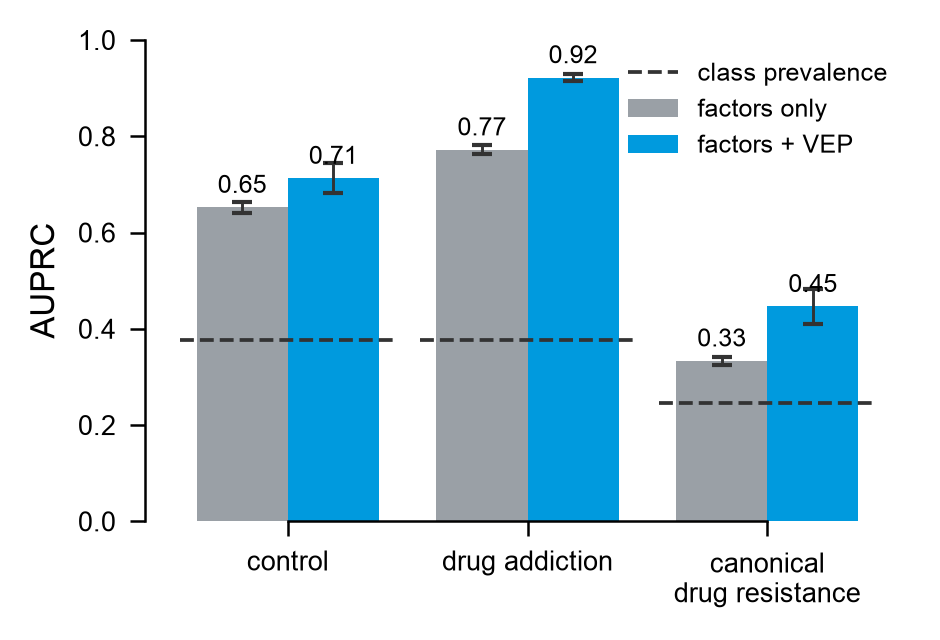

In [65]:
FACTORS = 15

bars = three_summary.loc[(slice(None), FACTORS), SUBTYPES].droplevel("factors")
errors = spread.loc[(slice(None), FACTORS), SUBTYPES].droplevel("factors")
ARMS = ["factors only", "factors + VEP"]

fig, ax = plt.subplots(figsize=(3, 2))
width = 0.38
positions = np.arange(len(SUBTYPES))
for offset, arm in zip([-width / 2, width / 2], ARMS):
    ax.bar(positions + offset, bars.loc[arm], width=width, yerr=errors.loc[arm],
           color=COLOUR[arm], label=arm, linewidth=0, capsize=2.5,
           error_kw=dict(lw=0.7, ecolor="#333333"))
    for position, value in zip(positions + offset, bars.loc[arm]):
        ax.text(position, value + 0.03, f"{value:.2f}", ha="center", fontsize=6)

# the floor a constant predictor reaches in each class
for position, name in zip(positions, SUBTYPES):
    ax.hlines(prevalence[name], position - 0.45, position + 0.45,
              color="#333333", lw=0.9, ls="--")

ax.set_xticks(positions, [n.replace(" drug", "\ndrug") for n in SUBTYPES], fontsize=7)
ax.set_ylabel("AUPRC")
ax.set_ylim(0, 1)
ax.tick_params(labelsize=6.5)
ax.plot([], [], color="#333333", lw=0.9, ls="--", label="class prevalence")
ax.legend(frameon=False, fontsize=6, loc="upper right")
fig.tight_layout(pad=0.3)
save_plot(fig, "perturbseq_auprc_by_class")
plt.show()